<a href="https://colab.research.google.com/github/joannasarah015-commits/metodosn-meros1/blob/main/Nevilleacabadoya.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#METODO DE NEVILLE

Dados $n+1$ puntos distintos $(x_0, f(x_0)), \dots, (x_n, f(x_n))$ y un punto $x$, el método calcula iterativamente aproximaciones en una tabla $Q$ con valores iniciales $Q_{i,0} = f(x_i)$. Para $i = 1, \dots, n$ y $j = 1, \dots, i$, se aplica:

$$Q_{i,j} = \frac{(x - x_{i-j})Q_{i,j-1} - (x - x_i)Q_{i-1,j-1}}{x_i - x_{i-j}}, \qquad P(x) = Q_{n,n}$$

**Ejemplo 2.** Los valores de diferentes polinomios de interpolación en $x = 1.5$ se obtuvieron usando los datos de la Tabla 3.5. Aplique el método de Neville a los datos mediante la construcción de una tabla recursiva:

* $x = [1.0, 1.3, 1.6, 1.9, 2.2]$
* $f(x) = [0.7651977, 0.6200860, 0.4554022, 0.2818186, 0.1103623]$


In [1]:
import numpy as np
import pandas as pd
import sympy as sp
from scipy.interpolate import barycentric_interpolate
import matplotlib.pyplot as plt

In [2]:
# Datos de la Tabla 3.5 y punto a evaluar
x_nodos = np.array([1.0, 1.3, 1.6, 1.9, 2.2], dtype=float)
y_nodos = np.array([0.7651977, 0.6200860, 0.4554022, 0.2818186, 0.1103623], dtype=float)
x_eval = 1.5

Ahora definimos el metodo de neville

In [4]:
def metodo_neville(x, xi, yi):
    n = len(xi) - 1
    Q = np.zeros((n + 1, n + 1))
    Q[:, 0] = yi

    for i in range(1, n + 1):
        for j in range(1, i + 1):
            num = (x - xi[i - j]) * Q[i, j - 1] - (x - xi[i]) * Q[i - 1, j - 1]
            den = xi[i] - xi[i - j]
            Q[i, j] = num / den

    return Q, Q[n, n]

tabla_Q, aproximacion = metodo_neville(x_eval, x_nodos, y_nodos)

Dibujamos la grafica:

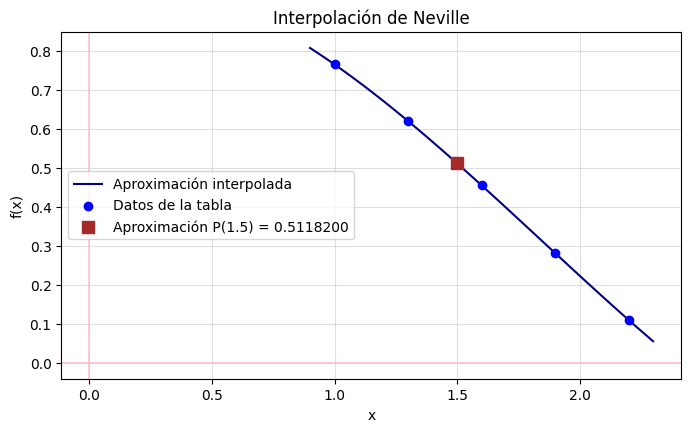

In [7]:
# Gráfica de los puntos y la aproximación en x = 1.5
x_graf = np.linspace(0.9, 2.3, 100)
y_graf = [metodo_neville(val, x_nodos, y_nodos)[1] for val in x_graf]

plt.figure(figsize=(8, 4.5))
plt.axhline(0, color="pink", linewidth=1.2)
plt.axvline(0, color="pink", linewidth=1.2)
plt.plot(x_graf, y_graf, label="Aproximación interpolada", color="navy")
plt.scatter(x_nodos, y_nodos, color="blue", label="Datos de la tabla", zorder=5)
plt.scatter([x_eval], [aproximacion], color="brown", marker="s", s=70,
            label=f"Aproximación P({x_eval}) = {aproximacion:.7f}", zorder=6)
plt.title("Interpolación de Neville")
plt.xlabel("x")
plt.ylabel("f(x)")
plt.grid(True, alpha=0.4)
plt.legend()
plt.show()

Crearemos la Tabla apartir de:

In [6]:
nombres_col = [f"Grado {j} (Q_i,{j})" for j in range(len(x_nodos))]
df = pd.DataFrame(tabla_Q, columns=nombres_col)
df.insert(0, "x_i", x_nodos)

# Para cambiar los ceros por espacios vacíos arriba de la diagonal
for i in range(len(x_nodos)):
    for j in range(i + 1, len(x_nodos)):
        df.iloc[i, j + 1] = np.nan

print(f"Tabla de iteraciones de Neville para x = {x_eval}:")
display(df.fillna(""))
print(f"\nSolución final -> P({x_eval}) = Q_{len(x_nodos)-1},{len(x_nodos)-1} = {aproximacion:.7f}")

Tabla de iteraciones de Neville para x = 1.5:


,x_i,"Grado 0 (Q_i,0)","Grado 1 (Q_i,1)","Grado 2 (Q_i,2)","Grado 3 (Q_i,3)","Grado 4 (Q_i,4)"
0,1.0,0.765198,,,,
1,1.3,0.620086,0.523345,,,
2,1.6,0.455402,0.510297,0.512471,,
3,1.9,0.281819,0.513263,0.511286,0.511813,
4,2.2,0.110362,0.510427,0.513736,0.51183,0.51182



Solución final -> P(1.5) = Q_4,4 = 0.5118200
